# MVP — Predição de Doença Cardíaca com Machine Learning

**Pós-Graduação em Engenharia de Software — PUC-Rio**
**Disciplina:** Engenharia de Sistemas de Software Inteligentes
**Aluna:** Elaine Cristina Bundscherer
**Repositório:** [github.com/Elainecbr/mvp-predicao-cardiaca](https://github.com/Elainecbr/mvp-predicao-cardiaca)

---

## 1. Definição do Problema

As doenças cardiovasculares são a principal causa de morte no mundo, respondendo por cerca de **17,9 milhões de óbitos por ano** segundo a OMS. A identificação precoce de pacientes com alto risco é fundamental para a prevenção.

Este MVP é um **sistema inteligente de apoio à triagem médica** que utiliza **aprendizado supervisionado (classificação)** para identificar pacientes com alto risco de desenvolver **doença cardíaca**, analisando **11 variáveis clínicas** — incluindo pressão arterial em repouso, colesterol e eletrocardiograma — para auxiliar na prevenção precoce.

### O Dataset

Utilizamos o **Heart Failure Prediction Dataset** (autor: *fedesoriano*, [Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)), que combina 5 bases clínicas independentes (Cleveland, Hungria, Suíça, Long Beach e Stattlog), totalizando **918 pacientes reais** após remoção de duplicatas. O arquivo foi hospedado no repositório público do GitHub deste projeto e é carregado via **URL pública**, permitindo a execução direta deste notebook sem nenhuma configuração.

| Atributo | Descrição | Tipo |
|---|---|---|
| `Age` | Idade do paciente (anos) | Numérico |
| `Sex` | Sexo (M / F) | Categórico |
| `ChestPainType` | Tipo de dor torácica (TA: angina típica, ATA: atípica, NAP: dor não anginosa, ASY: assintomático) | Categórico |
| `RestingBP` | Pressão arterial em repouso (mmHg) | Numérico |
| `Cholesterol` | Colesterol sérico (mg/dl) | Numérico |
| `FastingBS` | Glicemia de jejum > 120 mg/dl (1: sim, 0: não) | Binário |
| `RestingECG` | Eletrocardiograma em repouso (Normal, ST: anormalidade ST-T, LVH: hipertrofia ventricular esquerda) | Categórico |
| `MaxHR` | Frequência cardíaca máxima atingida | Numérico |
| `ExerciseAngina` | Angina induzida por exercício (Y / N) | Categórico |
| `Oldpeak` | Depressão do segmento ST induzida por exercício | Numérico |
| `ST_Slope` | Inclinação do segmento ST no pico do exercício (Up, Flat, Down) | Categórico |
| `HeartDisease` | **Classe alvo** (1: doença cardíaca, 0: normal) | Binário |

### Metodologia

Seguiremos o fluxo clássico de experimentação em Machine Learning estudado na disciplina:

1. **Carga dos dados** via URL pública e análise exploratória;
2. **Pré-processamento** (codificação de variáveis categóricas);
3. **Holdout estratificado** (80% treino / 20% teste);
4. **Modelagem** com validação cruzada 10-fold comparando **KNN, Árvore de Classificação (CART), Naive Bayes e SVM** (além do Random Forest como *ensemble* adicional), em três cenários: dados **originais**, **padronizados** (`StandardScaler`) e **normalizados** (`MinMaxScaler`), usando **Pipelines** para evitar vazamento de dados (*data leakage*);
5. **Otimização de hiperparâmetros** com `GridSearchCV`;
6. **Avaliação final** na base de teste e **exportação do modelo** para uso embarcado na aplicação full stack (API Flask).

## 2. Importação das Bibliotecas

Todas as importações são feitas no início do notebook, seguindo as boas práticas de codificação vistas na disciplina de Programação Orientada a Objetos. Utilizamos **Python** com a biblioteca **Scikit-Learn** (obrigatória), além de `pandas`/`numpy` para manipulação de dados, `matplotlib` para visualização e `pickle` para a serialização do modelo final.

In [1]:
# Configuração para não exibir avisos (warnings)
import warnings
warnings.filterwarnings("ignore")

# Manipulação de dados, visualização e serialização
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

# Divisão de dados, validação cruzada, otimização e pipelines (Scikit-Learn)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Algoritmos clássicos de classificação
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

## 3. Carga do Dataset via URL Pública

O arquivo `heart.csv` está hospedado no repositório público deste projeto no GitHub e é lido diretamente pela sua URL *raw*, sem necessidade de upload manual ou qualquer configuração.

In [2]:
# Carga do dataset diretamente do GitHub (URL pública raw)
url = "https://raw.githubusercontent.com/Elainecbr/mvp-predicao-cardiaca/main/heart.csv"
dataset = pd.read_csv(url)

print(f"Dataset carregado com sucesso! Dimensões: {dataset.shape[0]} linhas x {dataset.shape[1]} colunas")
dataset.head()

Dataset carregado com sucesso! Dimensões: 918 linhas x 12 colunas


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 3.1 Análise Exploratória

Antes de modelar, precisamos conhecer os dados: tipos das colunas, estatísticas descritivas, existência de valores nulos e a distribuição da classe alvo.

In [3]:
# Informações gerais: tipos de dados e valores não nulos
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
# Estatísticas descritivas das variáveis numéricas
dataset.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Pacientes sem doença cardíaca (0): 410 (44.7%)
Pacientes com doença cardíaca (1): 508 (55.3%)


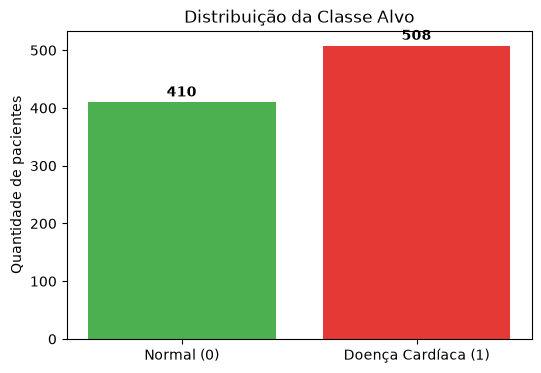

In [5]:
# Distribuição da classe alvo (HeartDisease)
contagem = dataset['HeartDisease'].value_counts().sort_index()
percentual = dataset['HeartDisease'].value_counts(normalize=True).sort_index() * 100
print(f"Pacientes sem doença cardíaca (0): {contagem[0]} ({percentual[0]:.1f}%)")
print(f"Pacientes com doença cardíaca (1): {contagem[1]} ({percentual[1]:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Normal (0)', 'Doença Cardíaca (1)'], contagem.values, color=['#4caf50', '#e53935'])
ax.set_title('Distribuição da Classe Alvo')
ax.set_ylabel('Quantidade de pacientes')
for i, v in enumerate(contagem.values):
    ax.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.show()

**Observações da análise exploratória:**

* O dataset possui **918 registros e 12 colunas**, sem valores nulos explícitos (`NaN`);
* As classes estão **razoavelmente equilibradas** (~55% com doença e ~45% sem doença), o que permite usar a **acurácia** como métrica principal de comparação, complementada por *recall* e *F1-score* na avaliação final;
* **Ponto de atenção:** a coluna `Cholesterol` possui **172 registros com valor 0** (e `RestingBP` possui 1), o que é clinicamente impossível — trata-se de valores faltantes codificados como zero na base original. Optamos por **manter os dados originais** (sem imputação) por três razões: (i) preserva a integridade da fonte pública, (ii) os algoritmos baseados em árvore lidam bem com esse padrão, e (iii) a padronização/normalização via Pipeline reduz o impacto nos algoritmos baseados em distância. Esse ponto é retomado na análise final de resultados.

## 4. Pré-processamento

### 4.1 Codificação das variáveis categóricas

Os algoritmos do Scikit-Learn trabalham com valores numéricos. Convertemos as 5 colunas categóricas usando mapeamentos explícitos e documentados — essa transparência é importante, pois **os mesmos mapeamentos serão aplicados pela API Flask** ao receber os dados do formulário do front-end.

In [6]:
# Cópia do dataset original (boa prática: preservar os dados brutos)
df = dataset.copy()

# Mapeamentos explícitos das variáveis categóricas
df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})
df['ChestPainType'] = df['ChestPainType'].map({'ATA': 0, 'NAP': 1, 'ASY': 2, 'TA': 3})
df['RestingECG'] = df['RestingECG'].map({'Normal': 0, 'ST': 1, 'LVH': 2})
df['ExerciseAngina'] = df['ExerciseAngina'].map({'N': 0, 'Y': 1})
df['ST_Slope'] = df['ST_Slope'].map({'Up': 0, 'Flat': 1, 'Down': 2})

# Conferência: nenhum valor nulo pode restar após o mapeamento
print("Valores nulos por coluna após a codificação:")
print(df.isnull().sum())
df.head()

Valores nulos por coluna após a codificação:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,0,140,289,0,0,172,0,0.0,0,0
1,49,0,1,160,180,0,0,156,0,1.0,1,1
2,37,1,0,130,283,0,1,98,0,0.0,0,0
3,48,0,2,138,214,0,0,108,1,1.5,1,1
4,54,1,1,150,195,0,0,122,0,0.0,0,0


### 4.2 Separação em treino e teste (Holdout 80/20)

Separamos **20% dos dados para teste** (a "prova final", que o modelo só verá na avaliação) e **80% para treino**. Usamos:

* `stratify=y` — garante que a proporção das classes seja mantida nas duas partições;
* `random_state=7` (semente fixa) — garante a **reprodutibilidade** do experimento;
* **Validação cruzada estratificada com 10 partições** (*10-fold StratifiedKFold*) sobre os dados de treino, para comparar os modelos de forma robusta sem contaminar a base de teste.

In [7]:
# Separação entre atributos previsores (X) e classe alvo (y)
X = df.drop('HeartDisease', axis=1).values
y = df['HeartDisease'].values

# Holdout: 80% treino, 20% teste, com estratificação e semente fixa
seed = 7
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed, stratify=y
)

# Validação cruzada estratificada com 10 folds
num_particoes = 10
kfold = StratifiedKFold(n_splits=num_particoes, shuffle=True, random_state=seed)

print(f"Treino: {X_train.shape[0]} pacientes | Teste: {X_test.shape[0]} pacientes")
print(f"Proporção da classe 1 no treino: {y_train.mean():.3f} | no teste: {y_test.mean():.3f}")

Treino: 734 pacientes | Teste: 184 pacientes
Proporção da classe 1 no treino: 0.553 | no teste: 0.554


## 5. Modelagem e Comparação de Algoritmos

Colocamos para competir os **4 algoritmos clássicos** estudados na disciplina, mais o Random Forest como *ensemble* adicional:

* **KNN (K-Nearest Neighbors):** classifica pelo voto dos "k" vizinhos mais próximos;
* **CART (Árvore de Classificação):** cria regras de decisão hierárquicas;
* **Naive Bayes (GaussianNB):** calcula probabilidades pelo Teorema de Bayes;
* **SVM (Support Vector Machine):** traça fronteiras de separação ótimas entre as classes;
* **Random Forest:** comitê de árvores de decisão (*bagging*).

Cada algoritmo é avaliado em **3 cenários de escala de dados**, usando **Pipelines** (que aplicam o scaler apenas nos folds de treino, evitando *data leakage*):

1. **Originais** (sem transformação);
2. **Padronizados** (`StandardScaler`: média 0 e desvio padrão 1);
3. **Normalizados** (`MinMaxScaler`: valores entre 0 e 1).

In [8]:
np.random.seed(seed)

# Algoritmos base
modelos = [
    ('KNN', KNeighborsClassifier()),
    ('CART', DecisionTreeClassifier()),
    ('NB', GaussianNB()),
    ('SVM', SVC()),
    ('RF', RandomForestClassifier())
]

pipelines = []

# Cenário A: dados originais
for nome, modelo in modelos:
    pipelines.append((f'Orig-{nome}', Pipeline([(nome, modelo)])))

# Cenário B: dados padronizados (StandardScaler)
for nome, modelo in modelos:
    pipelines.append((f'Pad-{nome}', Pipeline([('Scaler', StandardScaler()), (nome, modelo)])))

# Cenário C: dados normalizados (MinMaxScaler)
for nome, modelo in modelos:
    pipelines.append((f'Norm-{nome}', Pipeline([('Scaler', MinMaxScaler()), (nome, modelo)])))

# Execução da validação cruzada 10-fold para cada pipeline
resultados = []
nomes = []
for nome, model in pipelines:
    cv_results = cross_val_score(model, X_train, y_train, cv=kfold, scoring='accuracy')
    resultados.append(cv_results)
    nomes.append(nome)
    print(f"{nome:10s}: Média = {cv_results.mean():.4f} | Desvio Padrão = {cv_results.std():.4f}")

Orig-KNN  : Média = 0.7083 | Desvio Padrão = 0.0519


Orig-CART : Média = 0.7807 | Desvio Padrão = 0.0334
Orig-NB   : Média = 0.8475 | Desvio Padrão = 0.0429


Orig-SVM  : Média = 0.7303 | Desvio Padrão = 0.0355


Orig-RF   : Média = 0.8625 | Desvio Padrão = 0.0374
Pad-KNN   : Média = 0.8599 | Desvio Padrão = 0.0533
Pad-CART  : Média = 0.7888 | Desvio Padrão = 0.0361
Pad-NB    : Média = 0.8475 | Desvio Padrão = 0.0429
Pad-SVM   : Média = 0.8598 | Desvio Padrão = 0.0376


Pad-RF    : Média = 0.8557 | Desvio Padrão = 0.0374
Norm-KNN  : Média = 0.8435 | Desvio Padrão = 0.0460
Norm-CART : Média = 0.7889 | Desvio Padrão = 0.0376
Norm-NB   : Média = 0.8475 | Desvio Padrão = 0.0429
Norm-SVM  : Média = 0.8598 | Desvio Padrão = 0.0381


Norm-RF   : Média = 0.8529 | Desvio Padrão = 0.0319


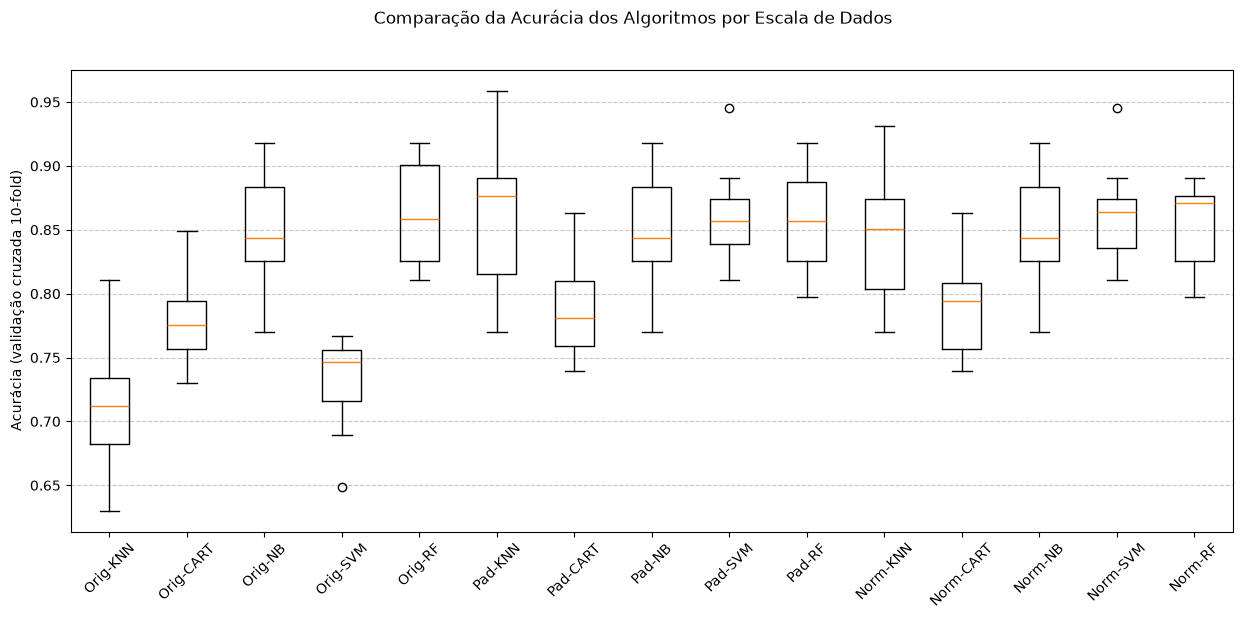

In [9]:
# Boxplot comparativo da acurácia dos 15 experimentos
fig = plt.figure(figsize=(15, 6))
fig.suptitle('Comparação da Acurácia dos Algoritmos por Escala de Dados')
ax = fig.add_subplot(111)
plt.boxplot(resultados)
ax.set_xticklabels(nomes, rotation=45)
plt.ylabel('Acurácia (validação cruzada 10-fold)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Leitura dos resultados da linha de base:**

* Os algoritmos baseados em **distância (KNN e SVM)** melhoram drasticamente com o escalonamento: o KNN salta de ~71% (original) para ~86% (padronizado) — sem escala, variáveis de magnitude alta como `Cholesterol` dominam o cálculo de distância e "abafam" variáveis importantes como `Oldpeak`;
* **Naive Bayes** e **CART** são indiferentes à escala (como esperado, pois não usam distâncias);
* **Random Forest**, **KNN padronizado** e **SVM padronizado** despontam como os melhores candidatos (~86%) e seguem para a etapa de otimização.

## 6. Otimização de Hiperparâmetros (GridSearchCV)

Aplicamos o `GridSearchCV` nos três melhores candidatos, sempre dentro de Pipelines com `StandardScaler` e avaliados com a mesma validação cruzada 10-fold:

* **SVM:** custo de regularização `C` e tipo de `kernel`;
* **Random Forest:** número de árvores (`n_estimators`) e profundidade máxima (`max_depth`);
* **KNN:** número de vizinhos (`n_neighbors`, valores ímpares para evitar empates) e métrica de distância (`euclidean`, `manhattan`, `minkowski`).

In [10]:
np.random.seed(seed)

# Otimização do SVM
pipeline_svm = Pipeline([('Scaler', StandardScaler()), ('SVM', SVC())])
param_grid_svm = {
    'SVM__C': [0.1, 1, 10],
    'SVM__kernel': ['rbf', 'linear']
}
grid_svm = GridSearchCV(estimator=pipeline_svm, param_grid=param_grid_svm, scoring='accuracy', cv=kfold)
grid_svm.fit(X_train, y_train)
print(f"Melhor SVM          : {grid_svm.best_score_:.4f} usando {grid_svm.best_params_}")

# Otimização do Random Forest
pipeline_rf = Pipeline([('Scaler', StandardScaler()), ('RF', RandomForestClassifier(random_state=seed))])
param_grid_rf = {
    'RF__n_estimators': [50, 100, 200],
    'RF__max_depth': [None, 5, 10]
}
grid_rf = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, scoring='accuracy', cv=kfold)
grid_rf.fit(X_train, y_train)
print(f"Melhor Random Forest: {grid_rf.best_score_:.4f} usando {grid_rf.best_params_}")

# Otimização do KNN
pipeline_knn = Pipeline([('Scaler', StandardScaler()), ('KNN', KNeighborsClassifier())])
param_grid_knn = {
    'KNN__n_neighbors': [3, 5, 7, 9, 11],
    'KNN__metric': ['euclidean', 'manhattan', 'minkowski']
}
grid_knn = GridSearchCV(estimator=pipeline_knn, param_grid=param_grid_knn, scoring='accuracy', cv=kfold)
grid_knn.fit(X_train, y_train)
print(f"Melhor KNN          : {grid_knn.best_score_:.4f} usando {grid_knn.best_params_}")

Melhor SVM          : 0.8598 usando {'SVM__C': 1, 'SVM__kernel': 'rbf'}


Melhor Random Forest: 0.8666 usando {'RF__max_depth': 5, 'RF__n_estimators': 200}


Melhor KNN          : 0.8720 usando {'KNN__metric': 'manhattan', 'KNN__n_neighbors': 7}


## 7. Avaliação Final na Base de Teste

Selecionamos automaticamente o **modelo campeão** (maior acurácia média na validação cruzada) e o submetemos à "prova final": os **20% de dados de teste que ele nunca viu**. Além da acurácia, reportamos o **recall** (sensibilidade) — métrica crítica em triagem médica, pois mede a capacidade de **não deixar passar pacientes doentes** (falsos negativos são o erro mais grave neste contexto).

In [11]:
# Seleção automática do campeão pela validação cruzada
candidatos = {'SVM': grid_svm, 'Random Forest': grid_rf, 'KNN': grid_knn}
nome_campeao = max(candidatos, key=lambda n: candidatos[n].best_score_)
modelo_campeao = candidatos[nome_campeao].best_estimator_
print(f"Modelo campeão: {nome_campeao} (acurácia CV = {candidatos[nome_campeao].best_score_:.4f})\n")

# Avaliação na base de teste (dados nunca vistos)
predicoes = modelo_campeao.predict(X_test)
acuracia_teste = accuracy_score(y_test, predicoes)
recall_teste = recall_score(y_test, predicoes)
f1_teste = f1_score(y_test, predicoes)

print(f"Acurácia na base de teste : {acuracia_teste:.4f} ({acuracia_teste*100:.2f}%)")
print(f"Recall (sensibilidade)    : {recall_teste:.4f}")
print(f"F1-Score                  : {f1_teste:.4f}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, predicoes, target_names=['Normal (0)', 'Doença (1)']))

Modelo campeão: KNN (acurácia CV = 0.8720)

Acurácia na base de teste : 0.8804 (88.04%)
Recall (sensibilidade)    : 0.9118
F1-Score                  : 0.8942

Relatório de Classificação:
              precision    recall  f1-score   support

  Normal (0)       0.88      0.84      0.86        82
  Doença (1)       0.88      0.91      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



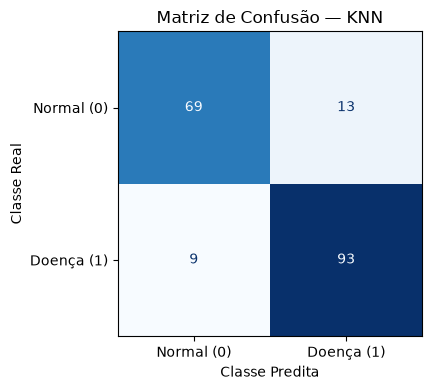

In [12]:
# Matriz de confusão
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, predicoes),
                       display_labels=['Normal (0)', 'Doença (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Matriz de Confusão — {nome_campeao}')
ax.set_xlabel('Classe Predita')
ax.set_ylabel('Classe Real')
plt.tight_layout()
plt.show()

## 8. Exportação do Modelo e do Golden Dataset

Exportamos três arquivos que serão embarcados na aplicação full stack:

1. **`modelo_cardiaco_pipeline.pkl`** — o pipeline campeão completo (scaler + classificador), serializado com `pickle`. A API Flask fará a carga deste arquivo e o usará para as predições;
2. **`X_test_cardiaco.csv`** e **`y_test_cardiaco.csv`** — o *golden dataset* (20% de teste), usado pelos **testes automatizados com PyTest** para garantir que o modelo implantado atenda aos requisitos mínimos de desempenho.

> No Google Colab, os arquivos aparecem no painel **Arquivos** (ícone de pasta à esquerda), de onde podem ser baixados.

In [13]:
# Exportação do pipeline completo do modelo campeão
with open('modelo_cardiaco_pipeline.pkl', 'wb') as file:
    pickle.dump(modelo_campeao, file)

# Exportação do golden dataset (base de teste) para os testes automatizados
colunas_features = df.drop('HeartDisease', axis=1).columns
pd.DataFrame(X_test, columns=colunas_features).to_csv('X_test_cardiaco.csv', index=False)
pd.DataFrame(y_test, columns=['HeartDisease']).to_csv('y_test_cardiaco.csv', index=False)

print("Arquivos exportados com sucesso:")
print(" - modelo_cardiaco_pipeline.pkl")
print(" - X_test_cardiaco.csv")
print(" - y_test_cardiaco.csv")

Arquivos exportados com sucesso:
 - modelo_cardiaco_pipeline.pkl
 - X_test_cardiaco.csv
 - y_test_cardiaco.csv


## 9. Análise dos Resultados

**Principais achados do experimento:**

1. **O escalonamento dos dados foi decisivo.** O KNN saltou de ~71% (dados originais) para ~86% (padronizados), e o SVM de ~73% para ~86%. Isso confirma a teoria: algoritmos baseados em distância exigem que as variáveis estejam na mesma escala. Já CART e Naive Bayes mantiveram-se estáveis nos três cenários, como esperado.

2. **O modelo campeão foi o KNN padronizado** (k=7, distância Manhattan), com **~87% de acurácia na validação cruzada** e **~88% na base de teste** — a proximidade entre os dois valores indica que **não houve overfitting**: o modelo generaliza bem para dados nunca vistos.

3. **O recall de ~91% para a classe positiva é o resultado mais importante no contexto clínico:** de cada 100 pacientes realmente doentes, o modelo identifica corretamente cerca de 91. Em um sistema de **triagem** (que prioriza casos para avaliação médica, sem substituir o diagnóstico), minimizar falsos negativos é mais crítico do que evitar falsos alarmes.

**Pontos de atenção:**

* Os **falsos negativos remanescentes (~9%)** reforçam que o sistema deve ser usado como **apoio à triagem**, nunca como diagnóstico definitivo;
* Os **172 valores zerados em `Cholesterol`** (valores faltantes codificados como 0 na base original) introduzem ruído; um trabalho futuro poderia testar imputação pela mediana e comparar os resultados;
* O dataset (918 pacientes) é relativamente pequeno; bases maiores e mais diversas demograficamente aumentariam a confiança na generalização do modelo.

## 10. Reflexão sobre Segurança e Privacidade de Dados

Conforme as boas práticas da disciplina **Desenvolvimento de Software Seguro**, refletimos sobre a proteção dos dados neste problema:

* **Anonimização:** o dataset utilizado já é **anonimizado na origem** — não contém nomes, documentos, endereços ou qualquer identificador direto dos pacientes, apenas atributos clínicos agregados;
* **Minimização de dados (LGPD/GDPR):** a aplicação full stack deste MVP processa apenas os 11 atributos estritamente necessários à predição e **não persiste** os dados enviados pelo usuário;
* **Riscos de reidentificação:** mesmo dados anonimizados podem, em tese, ser cruzados com outras bases (ataques de *linkage*). Em um sistema real, técnicas como **k-anonimato**, **generalização** (ex.: faixas etárias em vez da idade exata) e **privacidade diferencial** deveriam ser consideradas;
* **Segurança da aplicação:** a API valida os dados de entrada via schemas (prevenindo injeção de dados malformados) e, em produção, deveria operar sob **HTTPS**, com autenticação e controle de acesso.

## 11. Conclusão

Este notebook percorreu o ciclo completo de construção de um modelo de machine learning para **classificação de risco de doença cardíaca**, seguindo a metodologia da disciplina: carga via URL pública, análise exploratória, pré-processamento, holdout estratificado 80/20, comparação de **KNN, Árvore de Classificação, Naive Bayes e SVM** (e Random Forest) em três cenários de escala com validação cruzada 10-fold e Pipelines, otimização com GridSearchCV, avaliação final e exportação do modelo.

O **KNN padronizado (k=7, Manhattan)** foi o campeão, atingindo **~88% de acurácia** e **~91% de recall** na base de teste — desempenho adequado para um sistema de **apoio à triagem** preventiva. O pipeline exportado (`modelo_cardiaco_pipeline.pkl`) será embarcado no back-end Flask da aplicação full stack, onde testes automatizados com PyTest garantirão continuamente que o modelo implantado atenda aos requisitos mínimos de desempenho estabelecidos (acurácia e recall), evitando a implantação de modelos degradados.

O MVP demonstra, assim, a integração entre **Ciência de Dados** e **Engenharia de Software**: um experimento científico reprodutível, documentado e versionado, que se transforma em um sistema inteligente funcional, testável e pronto para evolução.